# Tratamiento de series temporales en RDBMS

## 1. Estructura de una serie temporal

Una serie temporal organiza observaciones según el tiempo. Cuando una base almacena varias series, debe distinguir qué observaciones pertenecen a cada una y cuál es su posición temporal [@hyndman2021].

Para una estación y una variable determinadas, una serie puede representarse como una secuencia de pares:

$$ S = \big((t_1,x_1), (t_2,x_2),\ldots,(t_n,x_n)\big), \qquad t_1 < t_2 < \cdots < t_n $$

Cada par relaciona un instante observado $t_i$ con un valor $x_i$. La desigualdad estricta supone que existe como máximo una observación por instante dentro de la serie, de acuerdo con la regla de unicidad adoptada.

La **identidad de la serie** y su **índice temporal** cumplen funciones diferentes:

| Elemento        | Función                           | Ejemplo                   |
|:----------------|:----------------------------------|:--------------------------|
| Identidad       | Distingue una serie de las demás. | Nivel de agua de E01.     |
| Índice temporal | Situa y ordena las observaciones. | `instante_observado_utc`. |
| Valor           | Representa la magnitud observada. | `nivel_cm`.               |

Por ejemplo, en el modelo proporcionado (`bd_temporal`) cada estación identifica una serie porque solo se registra una variable: nivel de agua en centímetros. Si se incorporaran otras variables, la identidad debería incluir la combinación estación–variable y conservar la unidad correspondiente.

Las filas de `lectura` almacenan las observaciones y su contexto: estación, instante observado y fecha de incorporación. La unidad queda expresada en el atributo `nivel_cm`. Un nivel nulo conserva la posición temporal de un registro recibido, aunque no aporte un valor utilizable.

Una tabla relacional no garantiza un orden de presentación. Para recuperar una serie ordenada se selecciona su identidad y se solicita explícitamente el orden temporal:

:::{code-block} sql
SELECT instante_observado_utc, nivel_cm
FROM lectura
WHERE estacion_id = 'E01'
ORDER BY instante_observado_utc;
:::

La consulta anterior devuelve las observaciones de E01, ordenadas desde el 19 de octubre a las `08:00` hasta el 20 de octubre a las `13:00`. Las tres observaciones de E02 pertenecen a otra serie y quedan excluidas.

Agrupar únicamente por hora podría mezclar estaciones y fechas. Asimismo, ordenar por `lectura_id` o por `registrado_utc` no sustituye el orden observado: una lectura antigua puede incorporarse después de otras más recientes. Por ejemplo, la lectura 6 pertenece al 19 de octubre a las `13:00`, aunque se cargó el día 20 a las `08:00`, su posición en la serie se determina con el instante observado.

## 2. Frecuencia y cobertura temporal

La frecuencia de observación establece cada cuánto se espera obtener un registro. En un muestreo regular, la separación entre instantes consecutivos es constante dentro del período considerado. En un muestreo irregular, puede variar porque las observaciones responden a eventos o a una programación variable.

La programación esperada debe diferenciarse de las observaciones recibidas. Una secuencia con separaciones variables puede corresponder a un muestreo irregular previsto o a registros faltantes de una programación regular. Los datos recibidos, por sí solos, no permiten decidir entre ambas situaciones.

Para identificar ausencias, el sistema debe conocer los instantes requeridos. Estos pueden definirse mediante una frecuencia y un período de operación, o mediante un calendario explícito. La **completitud de registros** se evalúa comparando esa expectativa con las filas disponibles.

Por ejemplo, se esperan seis registros diarios entre las 08:00 y las 13:00 UTC, separados por una hora. El 19 de octubre se presenta la siguiente situación:

| Estación | Horarios recibidos (UTC)                   | Horarios sin registro |Registros |
|:---:|:-------------------------------------------|:----------------------|:--------:|
| E01 | `08:00, 09:00, 10:00, 11:00, 12:00, 13:00` | -                     |   6/6    |
| E02 | `08:00, 09:00, 11:00`                      | `10:00, 12:00, 13:00` |   3/6    |

En E02, el salto entre las `09:00` y `11:00` indica una ausencia porque se esperaba un registro a las `10:00`. En una serie basada en eventos, ese mismo salto podría ser correcto. Tampoco se consideran faltantes los horarios fuera de la ventana programada.

Estos recuentos evalúan la presencia de registros, no la disponibilidad de valores. Una fila con `nivel_cm = NULL` es considerada como recibida, aunque no contenga una medición utilizable.

## 3. Cero, nulo y ausencia de registro

Una medición igual a cero, un atributo nulo y un registro ausente representan situaciones diferentes, cuya interpretación depende de las reglas del modelo.:
- Cero es un valor observado.
- `NULL` indica que el atributo carece de valor.
- La ausencia de fila indica que no existe un registro para ese instante.

 Esta distinción determina la forma de consultar los datos:

| Situación         | Identificación                          | Descripción                                |
|:------------------|:----------------------------------------|:-------------------------------------------|
| Valor cero        | `nivel_cm = 0`                          | Es un registro y tiene valor disponible.   |
| Valor nulo        | `nivel_cm IS NULL`                      | Es un registro, pero sin valor disponible. |
| Registro ausente  | Comparación con un calendario esperado. | No aporta una fila a la tabla de lecturas. |

Por tanto, `COUNT(*)` cuenta los registros recibidos y `COUNT(nivel_cm)` cuenta los que contienen un nivel no nulo. Ninguno permite identificar por sí solo todos los instantes sin registro.

Reemplazar nulos o registros ausentes por cero convertiría una falta de información en una medición. Si posteriormente se estiman valores mediante interpolación u otro procedimiento, deben identificarse como estimados y conservar la procedencia y la regla aplicada.

Por ejemplo, la estación E02 presenta las tres situaciones el 19 de octubre:

| Instante (UTC)  | Representación              | Interpretación                                          |
|:----------------|:----------------------------|:--------------------------------------------------------|
| `08:00`         | `nivel_cm = 0`.             | Se recibió una medición igual a cero.                   |
| `09:00`         | `nivel_cm IS NULL`.         | Se recibió un registro sin nivel utilizable.            |
| `10:00`         | No existe fila.             | Falta un registro previsto por la programación horaria. |

Para esos tres horarios esperados existen dos registros y un solo valor disponible. La medición cero se conserva como tal, el nulo y el registro ausente mantienen explícita la falta de información.

## 4. Representación gráfica de la serie

Una gráfica de serie temporal sitúa el tiempo observado en el eje horizontal y la variable, con su unidad, en el vertical. Permite examinar la secuencia de valores y su separación temporal. Debe conservar la identidad de la serie y utilizar la misma marca temporal que la consulta de origen.

Los puntos representan observaciones, las líneas que los unen facilitan seguir la secuencia. Los nulos y los registros ausentes deben tratarse explícitamente para evitar que una línea sugiera continuidad donde falta información.

Por ejemplo, la representación muestra las observaciones de E01:

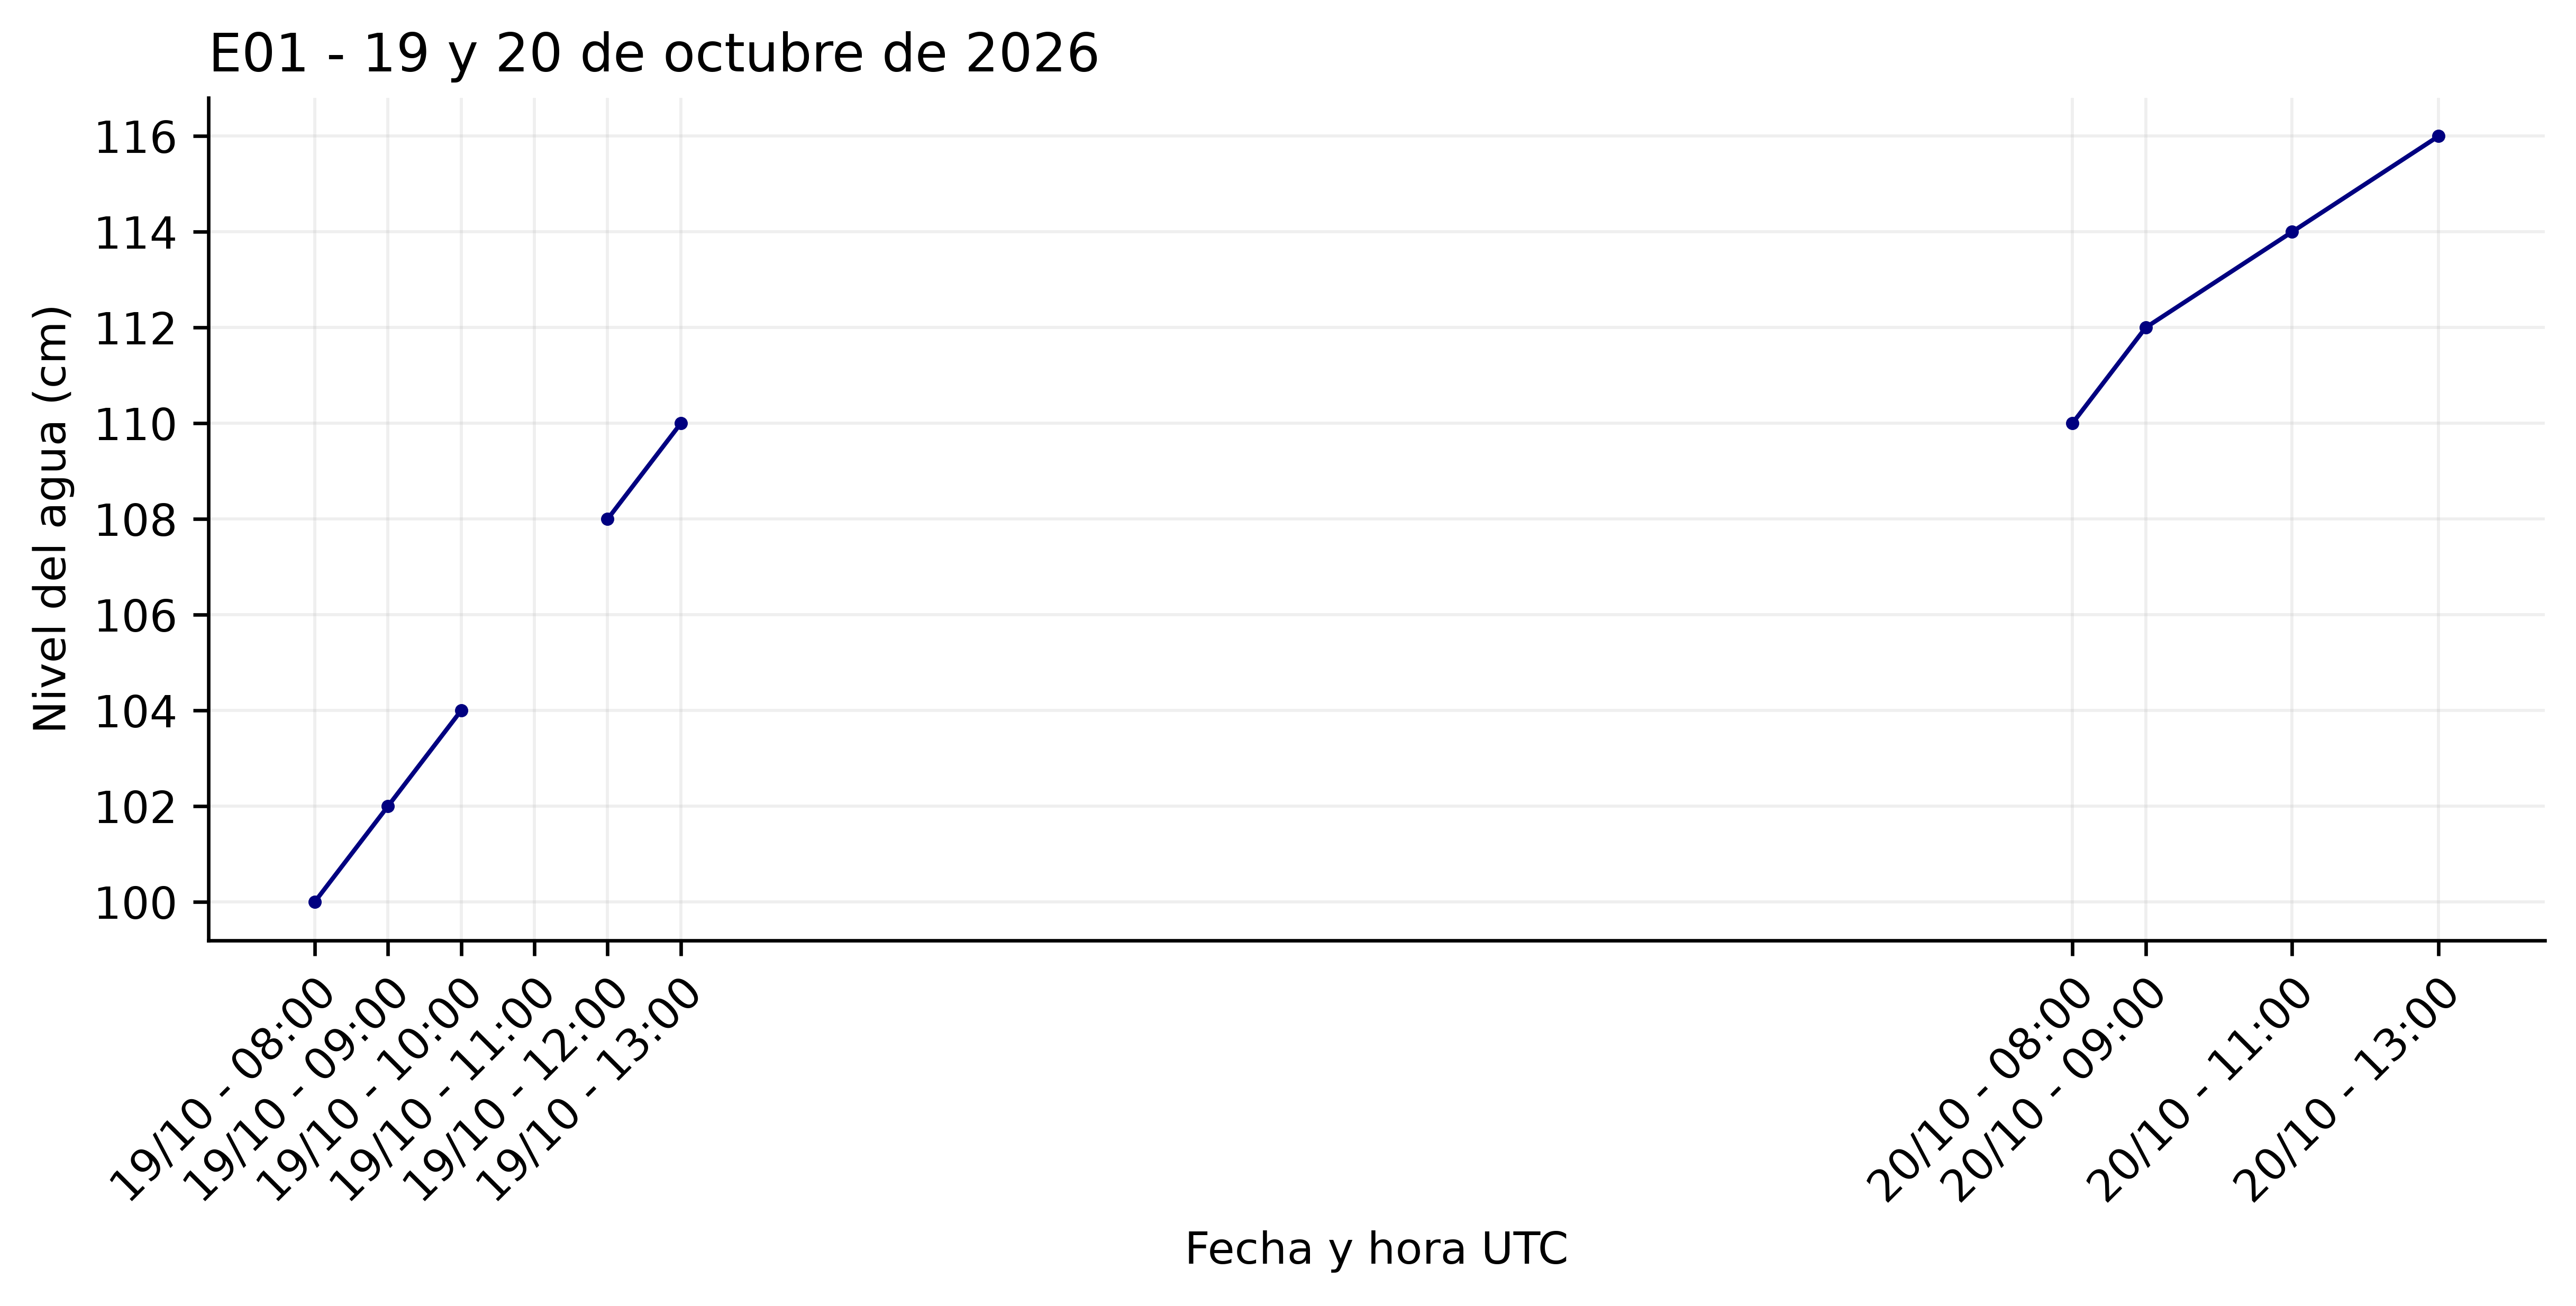

In [37]:
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.DataFrame({
    "tiempo": [
        datetime(2026, 10, dia, hora, tzinfo=timezone.utc)
        for dia, hora in [
            (19, 8), (19, 9), (19, 10), (19, 11), (19, 12), (19, 13),
            (20, 8), (20, 9), (20, 11), (20, 13)
        ]
    ],
    "nivel": [100, 102, 104, float("nan"), 108, 110, 110, 112, 114, 116]
})

fig, ax = plt.subplots(figsize=(8, 4), dpi=600, constrained_layout=True)

for _, grupo in df.groupby(df["tiempo"].dt.date):
    ax.plot(grupo["tiempo"], grupo["nivel"], "o-", color="navy", linewidth=1, markersize=2)

ax.set_xticks(t)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m - %H:%M", tz=timezone.utc))
ax.set(xlabel="Fecha y hora UTC", ylabel="Nivel del agua (cm)")
ax.set_title("E01 - 19 y 20 de octubre de 2026", loc="left")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

ax.grid(axis="both", alpha=0.2, linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)

plt.show()

## 5. Agregación temporal

Una agregación temporal resume observaciones en períodos definidos, como horas, días o meses. Para que el resultado sea interpretable, debe conservar la identidad de la serie, utilizar el campo temporal correspondiente y aplicar una operación adecuada a la variable.

En un resumen diario por estación, cada grupo reúne las lecturas de una misma estación observadas durante un día UTC:

:::{code-block} sql
:linenos:

SELECT estacion_id,
       DATE(instante_observado_utc) AS dia_utc,
       COUNT(*) AS registros,
       COUNT(nivel_cm) AS valores_disponibles,
       MIN(nivel_cm) AS minimo_cm,
       MAX(nivel_cm) AS maximo_cm,
       ROUND(AVG(nivel_cm), 2) AS promedio_cm
FROM lectura
GROUP BY estacion_id, DATE(instante_observado_utc)
ORDER BY estacion_id, dia_utc;
:::

- `DATE` extrae la fecha del instante observado.
- `GROUP BY` forma los grupos estación–día y las funciones de agregación calculan sus resúmenes.

| Función           | Resultado                             | Tratamiento de valores `NULL`            |
|:------------------|:--------------------------------------|:-----------------------------------------|
| `COUNT(*)`        | Cantidad de registros.                | Cuenta la fila aunque su nivel sea nulo. |
| `COUNT(nivel_cm)` | Cantidad de niveles disponibles.      | Excluye los niveles nulos.               |
| `MIN(nivel_cm)`   | Menor nivel disponible.               | Omite nulos.                             |
| `MAX(nivel_cm)`   | Mayor nivel disponible.               | Omite nulos.                             |
| `AVG(nivel_cm)`   | Promedio de los niveles disponibles.  | Omite nulos.                             |

Si un grupo no contiene niveles disponibles, `MIN`, `MAX` y `AVG` devuelven `NULL`, `COUNT(nivel_cm)` devuelve cero [@oracle_mysql80_aggregates].

El promedio describe los valores disponibles bajo las condiciones de selección. No representa necesariamente el nivel medio durante todo el día. Si algunos períodos contienen más lecturas, tienen mayor peso en el promedio simple. Un promedio ponderado por duración exigiría definir cómo se representa el nivel entre mediciones.

La operación también debe corresponder al significado de la variable. Sumar niveles instantáneos no produce automáticamente una cantidad física interpretable. En cambio, sumar cantidades acumuladas en períodos consecutivos puede ser pertinente si no existen superposiciones y las unidades son compatibles.